In [1]:
# # Gold EDA

# ## FINAURA — AI-Based Financial Market Regime Detection, Risk Forecasting & Portfolio Analytics

# This notebook performs Exploratory Data Analysis on the processed Gold dataset.

# ### Objectives
# - Understand the structure and quality of the Gold dataset
# - Analyze historical Gold price trends
# - Analyze daily and log returns
# - Study Gold volatility
# - Analyze moving averages and momentum
# - Examine drawdowns
# - Analyze trading volume
# - Study the future 5-day volatility target
# - Identify relationships between features and future volatility

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
input_path = Path("../data/processed/gold_processed.csv")

print("Input file:")
print(input_path)

Input file:
..\data\processed\gold_processed.csv


In [4]:
df = pd.read_csv(input_path)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (2380, 24)


In [5]:
df.head()

,date,adj_close,close,high,low,open,volume,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,volume_ma_20,volume_ratio,target_5d_volatility
0,2017-03-15,1200.099976,1200.099976,1221.199951,1197.699951,1198.199951,36,-0.001498,-0.001499,0.001586,0.019582,1201.500000,1211.300000,1227.889996,1213.640000,0.037482,0.070568,0.095917,-0.006951,-0.019446,-0.045570,196.80,0.182927,0.131764
1,2017-03-16,1226.500000,1226.500000,1231.400024,1222.199951,1222.199951,47,0.021998,0.021760,0.003518,0.007501,1206.319995,1210.759998,1227.629999,1214.962000,0.158972,0.131803,0.123242,0.020043,-0.004222,-0.024575,190.40,0.246849,0.068388
2,2017-03-17,1229.800049,1229.800049,1230.900024,1227.099976,1227.099976,26,0.002691,0.002687,0.002200,0.003090,1212.140015,1211.190002,1227.120001,1216.282000,0.152766,0.129747,0.121049,0.024236,-0.008226,-0.021950,187.35,0.138778,0.070286
3,2017-03-20,1233.599976,1233.599976,1234.400024,1229.300049,1229.300049,23,0.003090,0.003085,0.003498,0.004134,1218.380005,1212.100000,1226.920001,1217.360000,0.150890,0.130242,0.121522,0.025948,-0.003232,-0.018928,173.45,0.132603,0.073056
4,2017-03-21,1246.099976,1246.099976,1246.099976,1226.400024,1226.400024,11,0.010133,0.010082,0.016063,0.015809,1227.219995,1215.200000,1227.350000,1218.843999,0.144897,0.128541,0.126849,0.036775,0.006949,-0.008987,168.05,0.065457,0.046028


In [6]:
df.tail()

,date,adj_close,close,high,low,open,volume,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,volume_ma_20,volume_ratio,target_5d_volatility
2375,2026-08-25,4638.100098,4638.100098,4638.100098,4626.200195,4630.500000,321,-0.000582,-0.000582,0.001641,0.002566,4581.739941,4484.539941,4336.584961,4195.415991,0.202558,0.200085,0.209907,0.062323,0.149097,-0.127914,6189.45,0.051862,0.187022
2376,2026-08-26,4598.200195,4598.200195,4615.299805,4598.200195,4615.299805,1051,-0.008603,-0.008640,-0.003705,0.003719,4603.500000,4503.469971,4364.759973,4200.819995,0.188736,0.212520,0.215692,0.024235,0.139663,-0.135417,1758.80,0.597567,0.224069
2377,2026-08-27,4609.700195,4609.700195,4609.700195,4609.700195,4609.700195,5558,0.002501,0.002498,0.000000,0.000000,4622.180078,4528.079980,4390.239978,4206.396001,0.188975,0.197162,0.213095,0.020681,0.124290,-0.133254,1187.45,4.680618,0.222736
2378,2026-08-28,4478.100098,4478.100098,4625.500000,4451.799805,4599.299805,1758,-0.028549,-0.028964,-0.026352,0.038789,4592.980078,4537.850000,4411.689978,4208.780005,0.214051,0.262707,0.238399,-0.031574,0.105949,-0.157999,1217.05,1.444476,0.185910
2379,2026-08-31,4431.100098,4431.100098,4466.899902,4410.899902,4430.000000,360,-0.010496,-0.010551,0.000248,0.012638,4551.040137,4539.180029,4431.559985,4212.920005,0.195045,0.267292,0.242875,-0.045186,0.098520,-0.166836,1200.15,0.299963,0.259655


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2380 entries, 0 to 2379
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   date                  2380 non-null   object 
 1   adj_close             2380 non-null   float64
 2   close                 2380 non-null   float64
 3   high                  2380 non-null   float64
 4   low                   2380 non-null   float64
 5   open                  2380 non-null   float64
 6   volume                2380 non-null   int64  
 7   daily_return          2380 non-null   float64
 8   log_return            2380 non-null   float64
 9   intraday_return       2380 non-null   float64
 10  price_range           2380 non-null   float64
 11  ma_5                  2380 non-null   float64
 12  ma_10                 2380 non-null   float64
 13  ma_20                 2380 non-null   float64
 14  ma_50                 2380 non-null   float64
 15  volatility_5d        

In [8]:
rows, columns = df.shape

print("Number of rows:", rows)
print("Number of columns:", columns)

Number of rows: 2380
Number of columns: 24


In [9]:
print("Available columns:")

for col in df.columns:
    print(col)

Available columns:
date
adj_close
close
high
low
open
volume
daily_return
log_return
intraday_return
price_range
ma_5
ma_10
ma_20
ma_50
volatility_5d
volatility_10d
volatility_20d
momentum_5d
momentum_20d
drawdown
volume_ma_20
volume_ratio
target_5d_volatility


In [10]:
print(df.dtypes)

date                     object
adj_close               float64
close                   float64
high                    float64
low                     float64
open                    float64
volume                    int64
daily_return            float64
log_return              float64
intraday_return         float64
price_range             float64
ma_5                    float64
ma_10                   float64
ma_20                   float64
ma_50                   float64
volatility_5d           float64
volatility_10d          float64
volatility_20d          float64
momentum_5d             float64
momentum_20d            float64
drawdown                float64
volume_ma_20            float64
volume_ratio            float64
target_5d_volatility    float64
dtype: object


In [11]:
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

print("Date conversion completed.")
print(df["date"].dtype)

Date conversion completed.
datetime64[ns]


In [12]:
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

Start date: 2017-03-15 00:00:00
End date: 2026-08-31 00:00:00


In [13]:
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values)

Missing values:
date                    0
adj_close               0
close                   0
high                    0
low                     0
open                    0
volume                  0
daily_return            0
log_return              0
intraday_return         0
price_range             0
ma_5                    0
ma_10                   0
ma_20                   0
ma_50                   0
volatility_5d           0
volatility_10d          0
volatility_20d          0
momentum_5d             0
momentum_20d            0
drawdown                0
volume_ma_20            0
volume_ratio            0
target_5d_volatility    0
dtype: int64


In [14]:
duplicate_rows = df.duplicated().sum()

print("Duplicate rows:", duplicate_rows)

Duplicate rows: 0


In [15]:
df.describe()

,date,adj_close,close,high,low,open,volume,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,volume_ma_20,volume_ratio,target_5d_volatility
count,2380,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000,2380.000000
mean,2021-12-06 05:55:09.579831808,2097.873401,2097.873401,2109.471346,2085.881555,2097.640799,5013.231092,0.000606,0.000548,0.000178,0.009926,2095.103846,2091.554287,2084.775829,2066.080922,0.144290,0.150398,0.153597,0.003065,0.011735,-0.063647,5008.591008,0.911915,0.144473
min,2017-03-15 00:00:00,1176.199951,1176.199951,1180.199951,1161.400024,1173.199951,0.000000,-0.113662,-0.120657,-0.123224,0.000000,1181.919995,1188.350012,1193.725006,1197.667998,0.018791,0.033695,0.050614,-0.120316,-0.154738,-0.250602,14.600000,0.000000,0.018791
25%,2019-07-28 06:00:00,1425.250031,1425.250031,1435.350037,1421.474976,1426.050049,57.000000,-0.004185,-0.004194,-0.003357,0.004392,1421.529993,1419.985004,1411.711247,1364.208995,0.086090,0.101218,0.108138,-0.009695,-0.015653,-0.102251,345.262500,0.034114,0.086219
50%,2021-12-04 12:00:00,1821.399963,1821.399963,1829.300049,1814.000000,1820.900024,235.000000,0.000806,0.000806,0.000000,0.008076,1821.640015,1823.400012,1821.222501,1818.486001,0.122671,0.129192,0.134204,0.003350,0.007057,-0.049961,1132.725000,0.129673,0.122781
75%,2024-04-18 06:00:00,2312.699951,2312.699951,2324.899963,2296.649963,2310.974976,707.500000,0.006054,0.006035,0.004551,0.013054,2316.624963,2317.382489,2289.285010,2166.319996,0.177914,0.175161,0.172851,0.015565,0.038046,-0.021221,9447.812500,0.502865,0.178254
max,2026-08-31 00:00:00,5318.399902,5318.399902,5586.200195,5301.600098,5415.700195,386334.000000,0.060833,0.059054,0.047799,0.157089,5212.719922,5170.729980,5119.044971,4951.807979,1.122901,0.771563,0.583978,0.115988,0.225775,0.000000,22654.000000,19.982214,1.122901
std,NaN,942.415265,942.415265,952.441465,932.450946,942.996346,27733.786514,0.010682,0.010722,0.009169,0.009254,939.761067,936.291690,930.024363,914.962095,0.092673,0.082469,0.074272,0.023094,0.042880,0.053661,5963.627333,2.941672,0.092713


In [16]:
close_columns = [
    col for col in df.columns
    if "close" in col.lower()
]

print("Close-related columns:")
print(close_columns)

Close-related columns:
['adj_close', 'close']


In [17]:
if "close" in df.columns:
    price_column = "close"
elif "gold_close" in df.columns:
    price_column = "gold_close"
else:
    price_column = close_columns[0]

print("Selected price column:", price_column)

Selected price column: close


In [18]:
price_stats = df[price_column].describe()

price_stats

count    2380.000000
mean     2097.873401
std       942.415265
min      1176.199951
25%      1425.250031
50%      1821.399963
75%      2312.699951
max      5318.399902
Name: close, dtype: float64

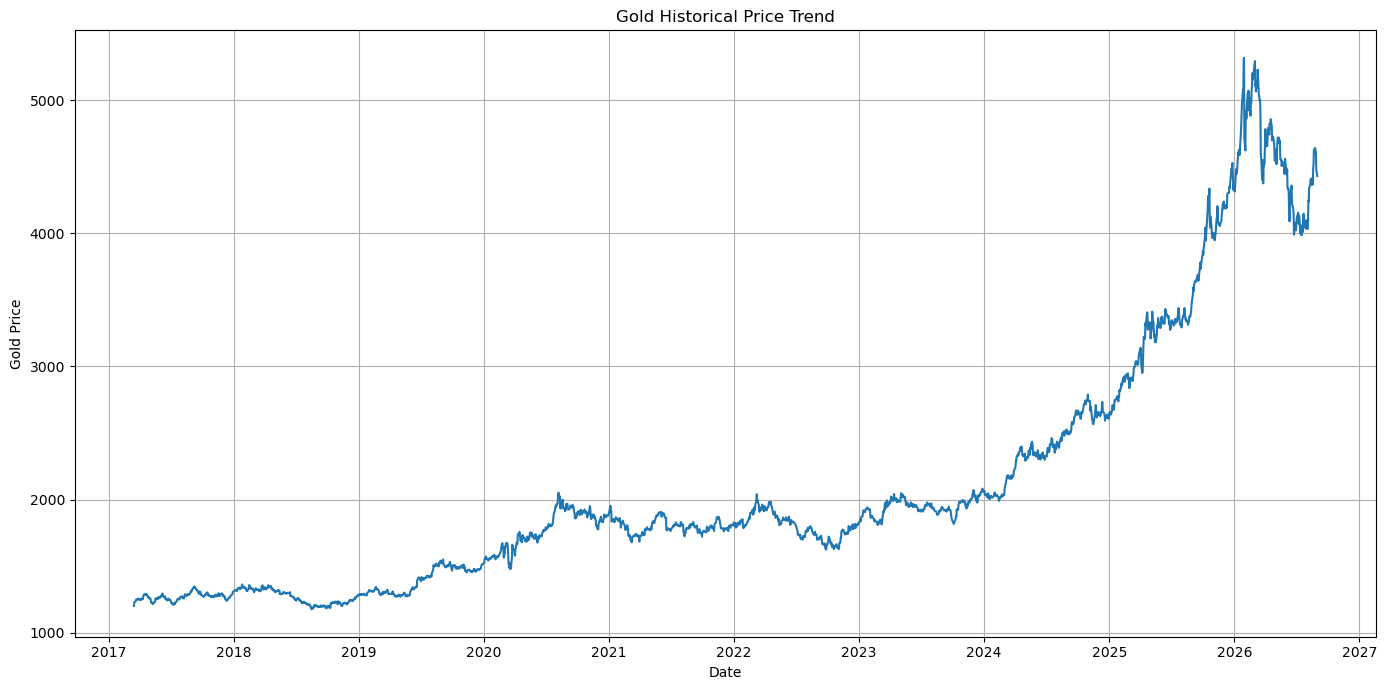

In [19]:
plt.figure(figsize=(14, 7))

plt.plot(
    df["date"],
    df[price_column]
)

plt.title("Gold Historical Price Trend")
plt.xlabel("Date")
plt.ylabel("Gold Price")
plt.grid(True)
plt.tight_layout()
plt.show()

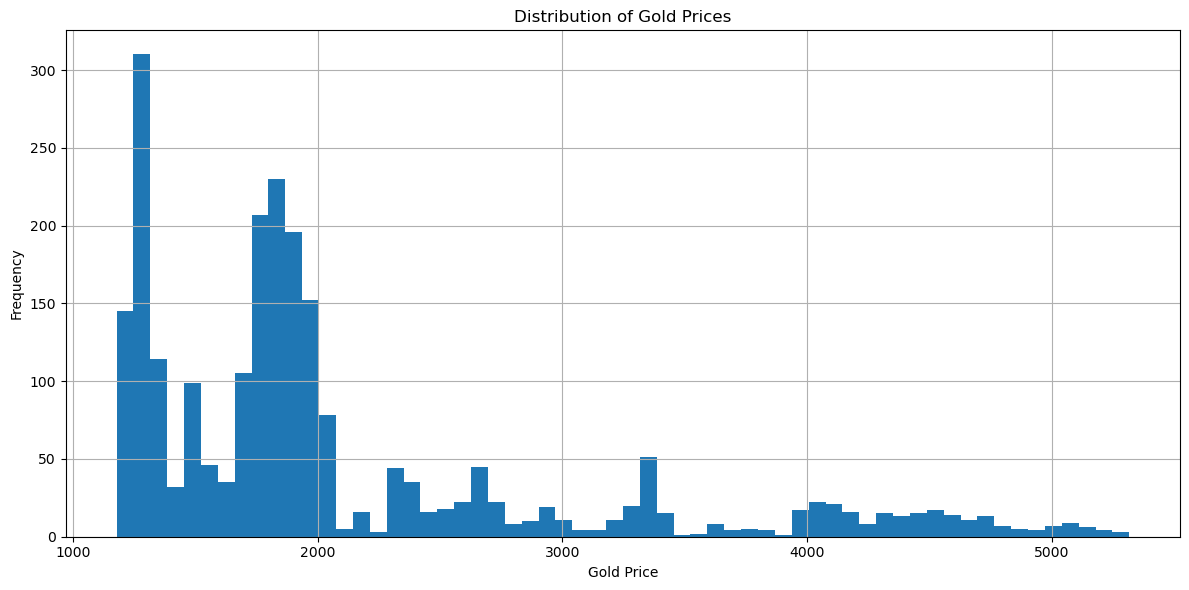

In [20]:
plt.figure(figsize=(12, 6))

plt.hist(
    df[price_column].dropna(),
    bins=60
)

plt.title("Distribution of Gold Prices")
plt.xlabel("Gold Price")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

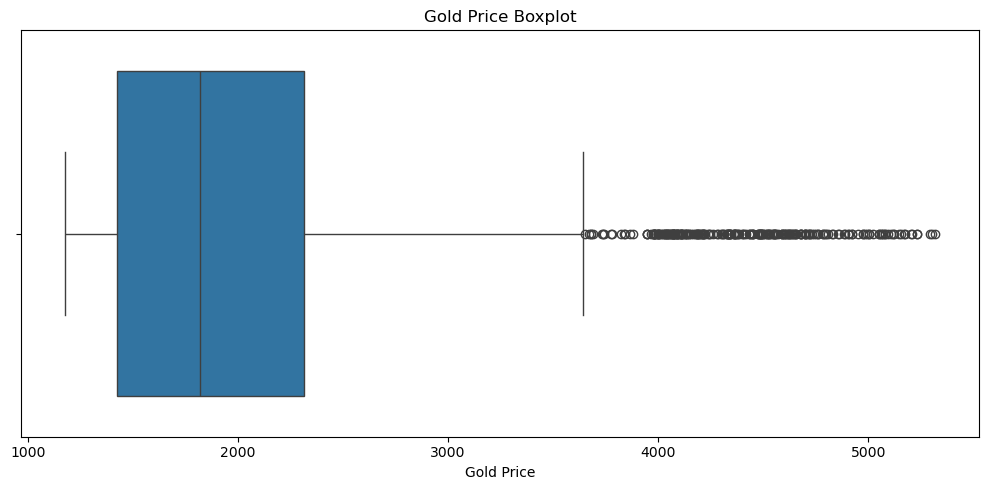

In [21]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df[price_column].dropna()
)

plt.title("Gold Price Boxplot")
plt.xlabel("Gold Price")
plt.tight_layout()
plt.show()

In [22]:
return_columns = [
    col for col in df.columns
    if "return" in col.lower()
]

print("Return columns:")
print(return_columns)

Return columns:
['daily_return', 'log_return', 'intraday_return']


In [23]:
if "daily_return" in df.columns:
    df["daily_return"].describe()

elif "return" in df.columns:
    df["return"].describe()

else:
    print("Daily return column not found.")

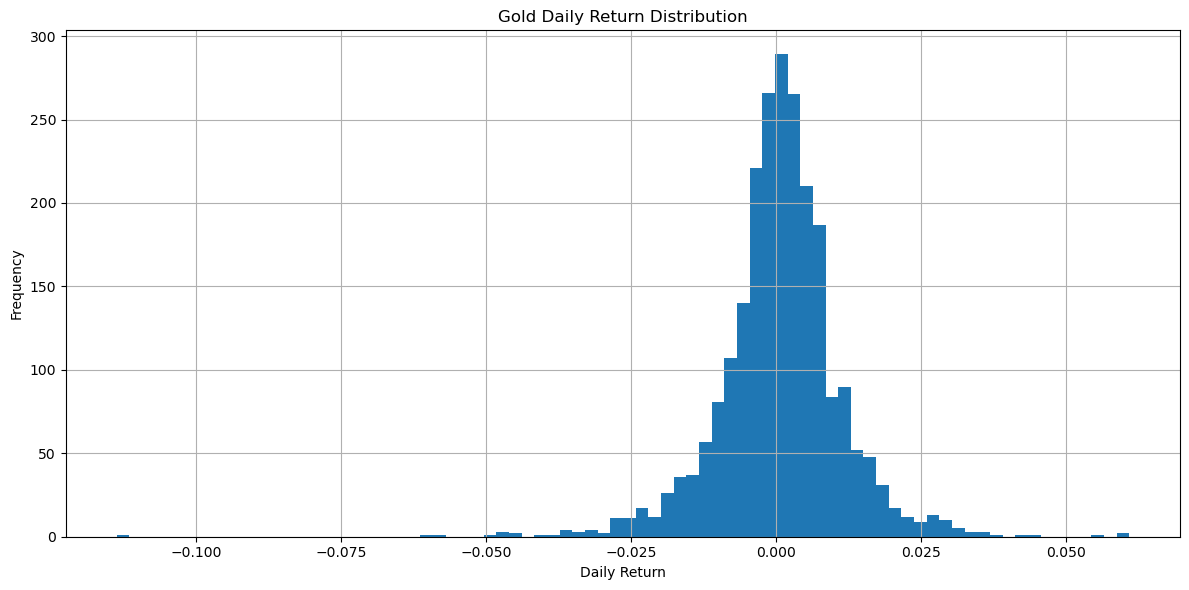

In [24]:
if "daily_return" in df.columns:

    plt.figure(figsize=(12, 6))

    plt.hist(
        df["daily_return"].dropna(),
        bins=80
    )

    plt.title("Gold Daily Return Distribution")
    plt.xlabel("Daily Return")
    plt.ylabel("Frequency")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

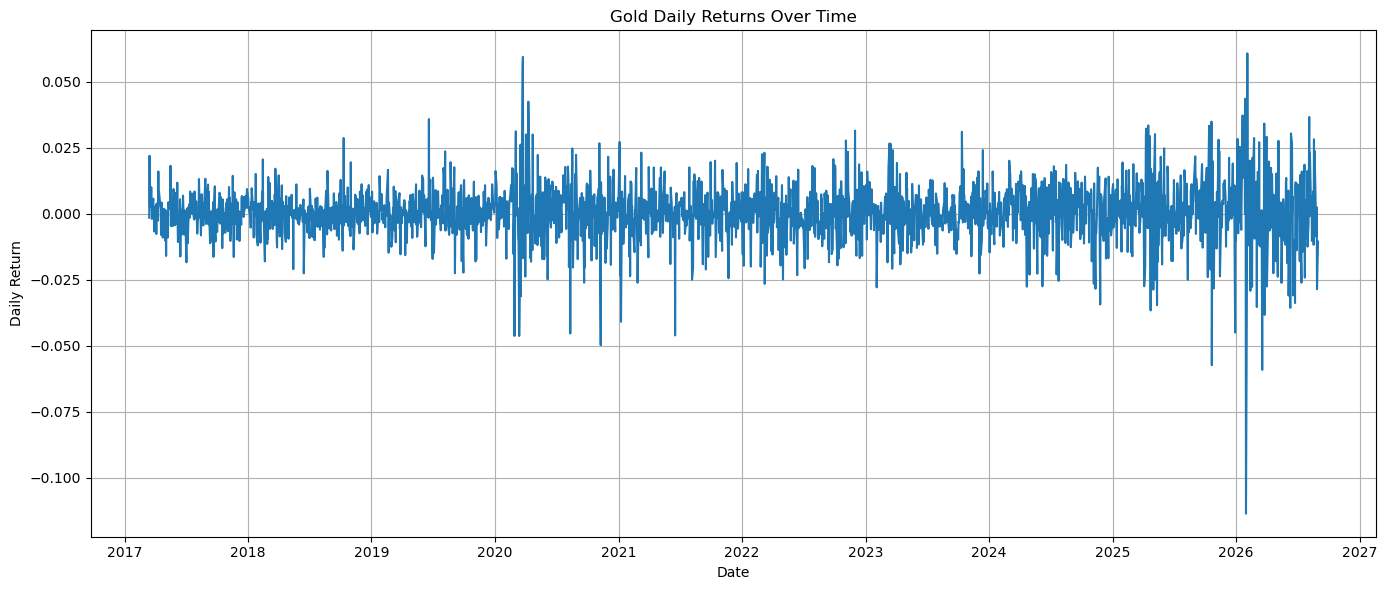

In [25]:
if "daily_return" in df.columns:

    plt.figure(figsize=(14, 6))

    plt.plot(
        df["date"],
        df["daily_return"]
    )

    plt.title("Gold Daily Returns Over Time")
    plt.xlabel("Date")
    plt.ylabel("Daily Return")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [26]:
if "daily_return" in df.columns:

    return_stats = df["daily_return"].agg(
        ["mean", "std", "min", "max", "median"]
    )

    return_stats

In [27]:
volatility_columns = [
    col for col in df.columns
    if "volatility" in col.lower()
]

print("Volatility columns:")
print(volatility_columns)

Volatility columns:
['volatility_5d', 'volatility_10d', 'volatility_20d', 'target_5d_volatility']


In [28]:
if "volatility_20d" in df.columns:
    volatility_col = "volatility_20d"

elif "volatility_20" in df.columns:
    volatility_col = "volatility_20"

else:
    volatility_col = volatility_columns[-1]

print("Selected volatility column:", volatility_col)

Selected volatility column: volatility_20d


In [29]:
volatility_stats = df[volatility_col].describe()

volatility_stats

count    2380.000000
mean        0.153597
std         0.074272
min         0.050614
25%         0.108138
50%         0.134204
75%         0.172851
max         0.583978
Name: volatility_20d, dtype: float64

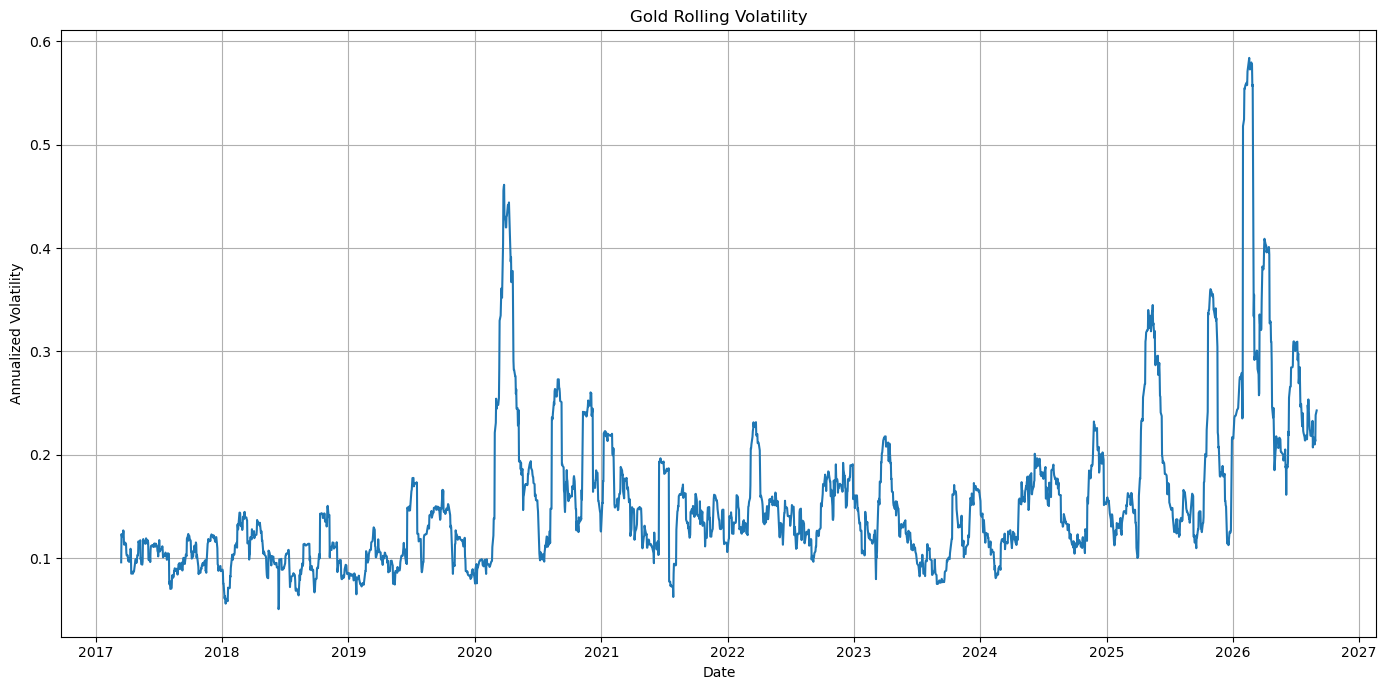

In [30]:
plt.figure(figsize=(14, 7))

plt.plot(
    df["date"],
    df[volatility_col]
)

plt.title("Gold Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.grid(True)
plt.tight_layout()
plt.show()

In [31]:
highest_volatility = (
    df[
        ["date", volatility_col]
    ]
    .dropna()
    .sort_values(
        volatility_col,
        ascending=False
    )
    .head(20)
)

highest_volatility

,date,volatility_20d
2244,2026-02-17,0.583978
2248,2026-02-23,0.579562
2250,2026-02-25,0.577628
2249,2026-02-24,0.576753
2245,2026-02-18,0.574636
2243,2026-02-13,0.573511
2247,2026-02-20,0.573099
2246,2026-02-19,0.572823
2242,2026-02-12,0.570898
2239,2026-02-09,0.559889


In [32]:
ma_columns = [
    col for col in df.columns
    if col.lower().startswith("ma_")
]

print("Moving average columns:")
print(ma_columns)

Moving average columns:
['ma_5', 'ma_10', 'ma_20', 'ma_50']


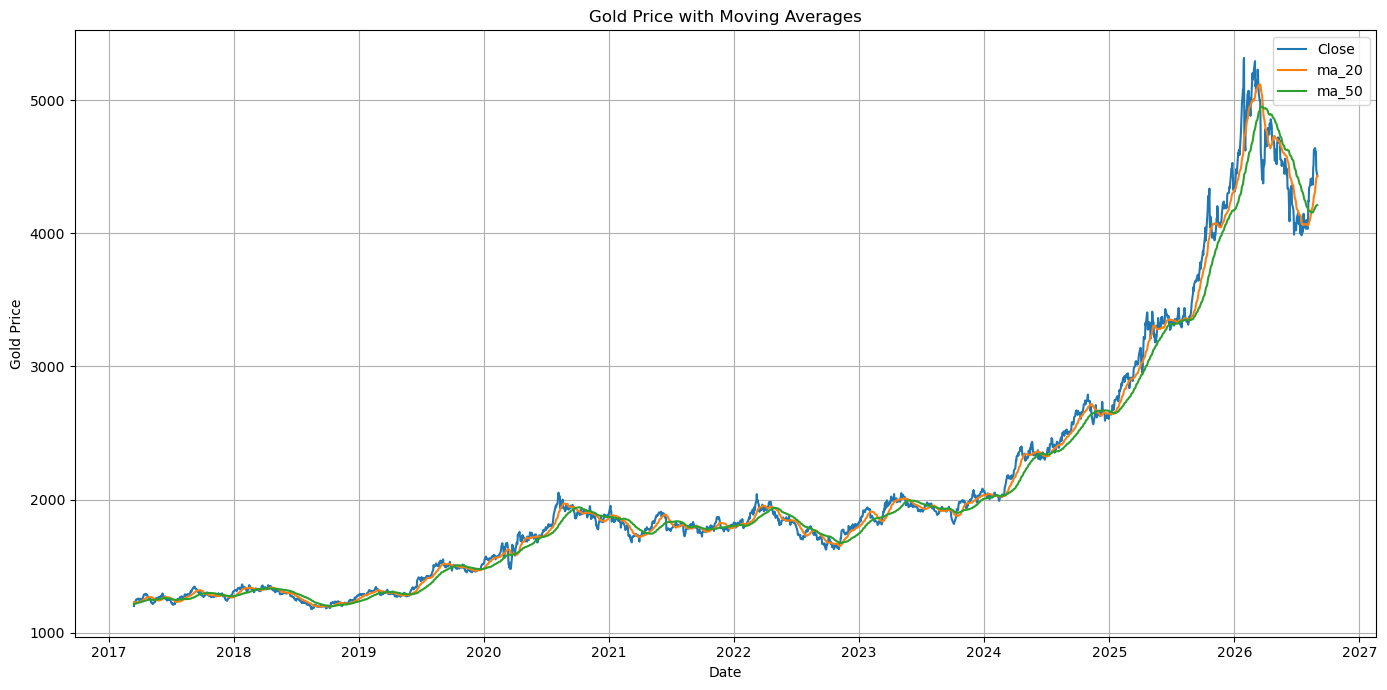

In [33]:
plt.figure(figsize=(14, 7))

plt.plot(
    df["date"],
    df[price_column],
    label="Close"
)

for ma in ["ma_20", "ma_50"]:
    if ma in df.columns:
        plt.plot(
            df["date"],
            df[ma],
            label=ma
        )

plt.title("Gold Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Gold Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [34]:
momentum_columns = [
    col for col in df.columns
    if "momentum" in col.lower()
]

print("Momentum columns:")
print(momentum_columns)

Momentum columns:
['momentum_5d', 'momentum_20d']


In [35]:
if momentum_columns:
    momentum_stats = df[momentum_columns].describe()
    momentum_stats
else:
    print("Momentum columns not found.")

In [36]:
if "momentum_20" in df.columns:

    plt.figure(figsize=(14, 6))

    plt.plot(
        df["date"],
        df["momentum_20"]
    )

    plt.title("Gold 20-Day Momentum")
    plt.xlabel("Date")
    plt.ylabel("Momentum")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [37]:
drawdown_stats = df["drawdown"].describe()

drawdown_stats

count    2380.000000
mean       -0.063647
std         0.053661
min        -0.250602
25%        -0.102251
50%        -0.049961
75%        -0.021221
max         0.000000
Name: drawdown, dtype: float64

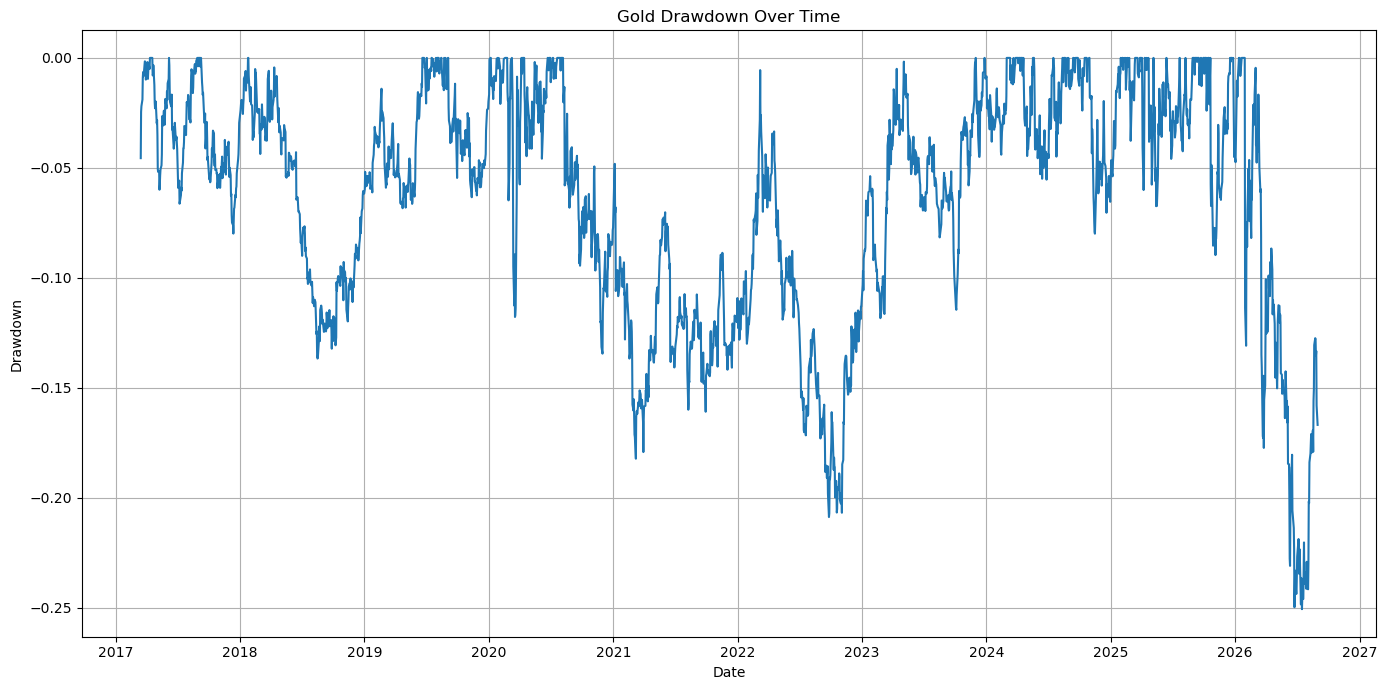

In [38]:
plt.figure(figsize=(14, 7))

plt.plot(
    df["date"],
    df["drawdown"]
)

plt.title("Gold Drawdown Over Time")
plt.xlabel("Date")
plt.ylabel("Drawdown")
plt.grid(True)
plt.tight_layout()
plt.show()

In [39]:
maximum_drawdown = df["drawdown"].min()

print(
    "Maximum drawdown:",
    round(maximum_drawdown, 4)
)

Maximum drawdown: -0.2506


In [40]:
if "volume" in df.columns:

    print("Volume statistics:")
    print(df["volume"].describe())

else:
    print("Volume column not available.")

Volume statistics:
count      2380.000000
mean       5013.231092
std       27733.786514
min           0.000000
25%          57.000000
50%         235.000000
75%         707.500000
max      386334.000000
Name: volume, dtype: float64


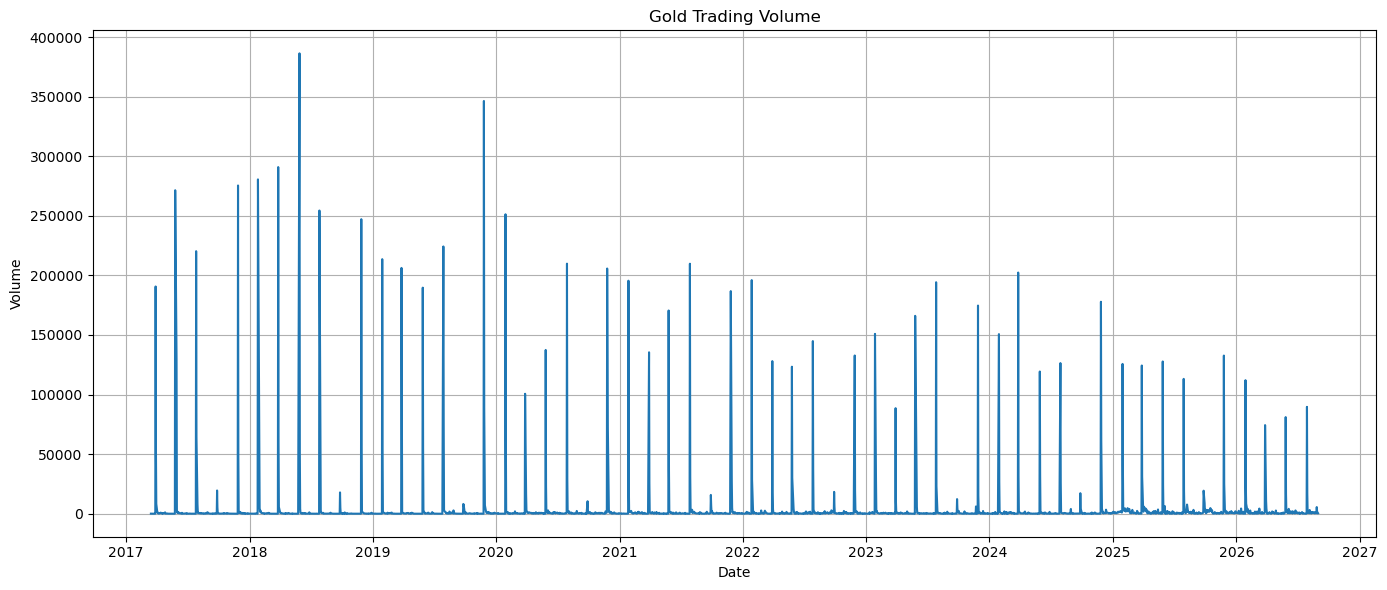

In [41]:
if "volume" in df.columns:

    plt.figure(figsize=(14, 6))

    plt.plot(
        df["date"],
        df["volume"]
    )

    plt.title("Gold Trading Volume")
    plt.xlabel("Date")
    plt.ylabel("Volume")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [42]:
target_column = "target_5d_volatility"

print("Target column:", target_column)

print("\nTarget statistics:")
print(df[target_column].describe())

Target column: target_5d_volatility

Target statistics:
count    2380.000000
mean        0.144473
std         0.092713
min         0.018791
25%         0.086219
50%         0.122781
75%         0.178254
max         1.122901
Name: target_5d_volatility, dtype: float64


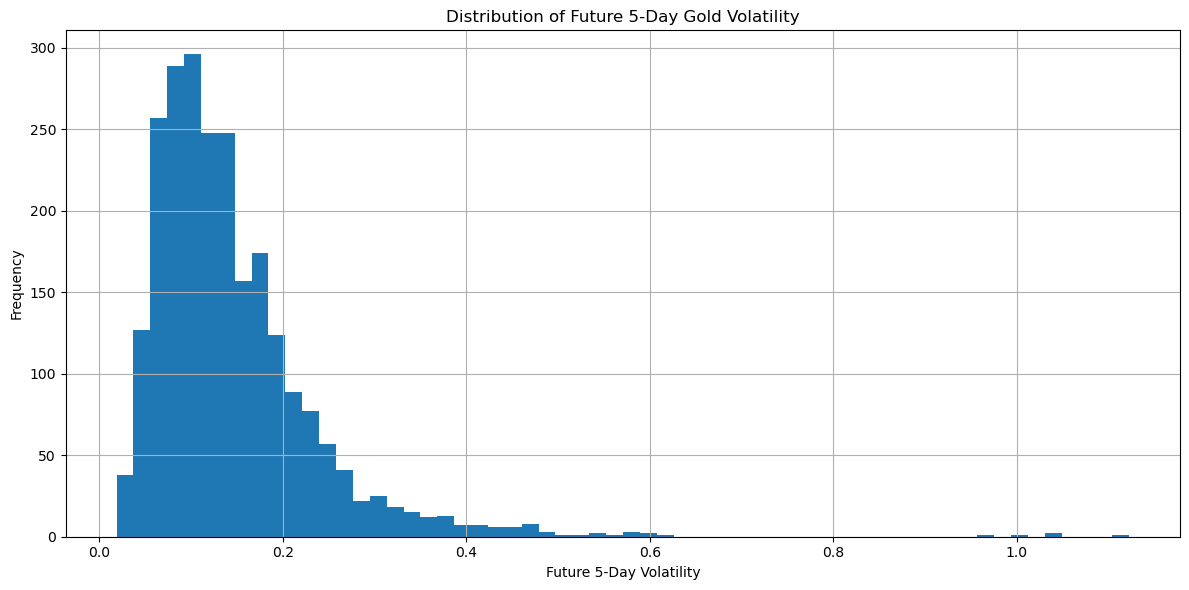

In [43]:
plt.figure(figsize=(12, 6))

plt.hist(
    df[target_column].dropna(),
    bins=60
)

plt.title("Distribution of Future 5-Day Gold Volatility")
plt.xlabel("Future 5-Day Volatility")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

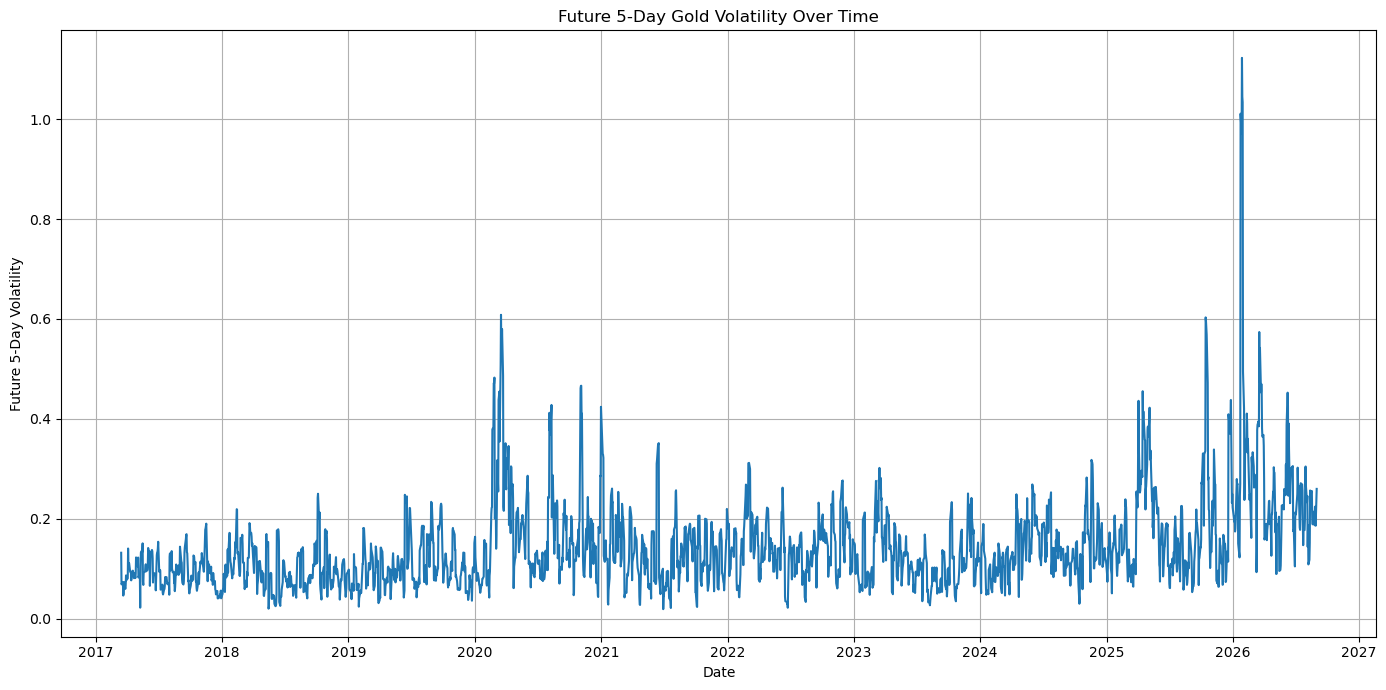

In [44]:
plt.figure(figsize=(14, 7))

plt.plot(
    df["date"],
    df[target_column]
)

plt.title("Future 5-Day Gold Volatility Over Time")
plt.xlabel("Date")
plt.ylabel("Future 5-Day Volatility")
plt.grid(True)
plt.tight_layout()
plt.show()

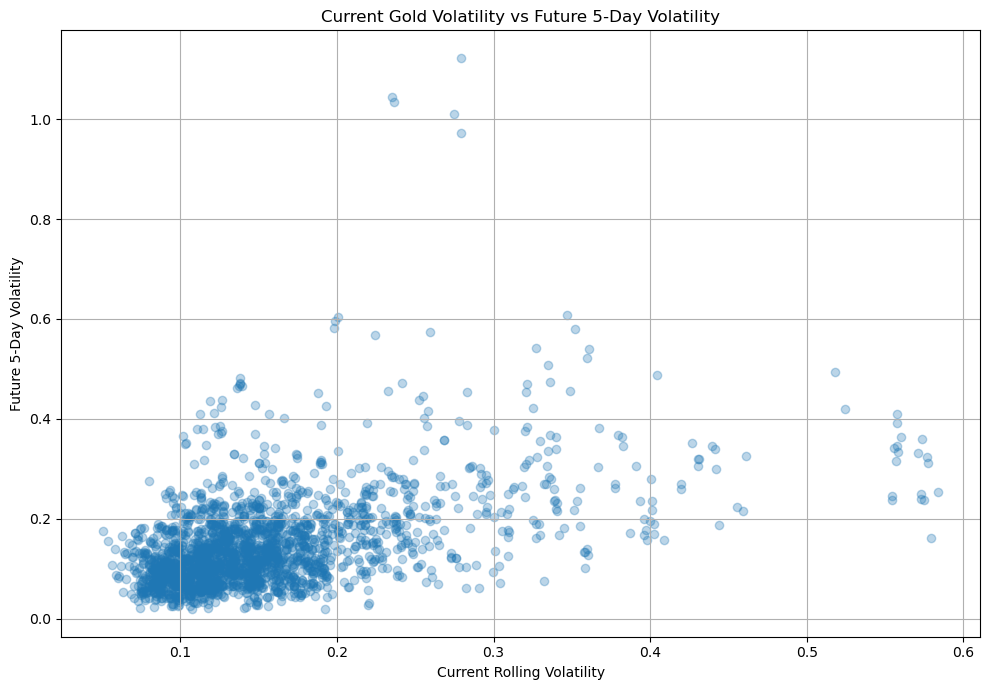

In [45]:
plt.figure(figsize=(10, 7))

plt.scatter(
    df[volatility_col],
    df[target_column],
    alpha=0.3
)

plt.title("Current Gold Volatility vs Future 5-Day Volatility")
plt.xlabel("Current Rolling Volatility")
plt.ylabel("Future 5-Day Volatility")
plt.grid(True)
plt.tight_layout()
plt.show()

In [46]:
numeric_df = df.select_dtypes(
    include=np.number
)

correlation_matrix = numeric_df.corr()

print(
    "Correlation matrix shape:",
    correlation_matrix.shape
)

Correlation matrix shape: (23, 23)


In [47]:
target_correlations = (
    correlation_matrix[target_column]
    .sort_values(ascending=False)
)

target_correlations

target_5d_volatility    1.000000
volatility_20d          0.483629
high                    0.472461
open                    0.470866
close                   0.468995
adj_close               0.468995
ma_5                    0.467677
low                     0.466653
ma_10                   0.465436
ma_20                   0.461173
volatility_10d          0.456900
ma_50                   0.448418
volatility_5d           0.386365
price_range             0.362366
momentum_20d            0.200955
momentum_5d             0.091383
volume_ratio            0.044917
daily_return            0.028186
log_return              0.023898
volume                  0.005640
drawdown               -0.035440
intraday_return        -0.043115
volume_ma_20           -0.068616
Name: target_5d_volatility, dtype: float64

In [48]:
strongest_features = (
    target_correlations
    .drop(target_column)
    .sort_values(
        key=abs,
        ascending=False
    )
)

strongest_features.head(15)

volatility_20d    0.483629
high              0.472461
open              0.470866
close             0.468995
adj_close         0.468995
ma_5              0.467677
low               0.466653
ma_10             0.465436
ma_20             0.461173
volatility_10d    0.456900
ma_50             0.448418
volatility_5d     0.386365
price_range       0.362366
momentum_20d      0.200955
momentum_5d       0.091383
Name: target_5d_volatility, dtype: float64

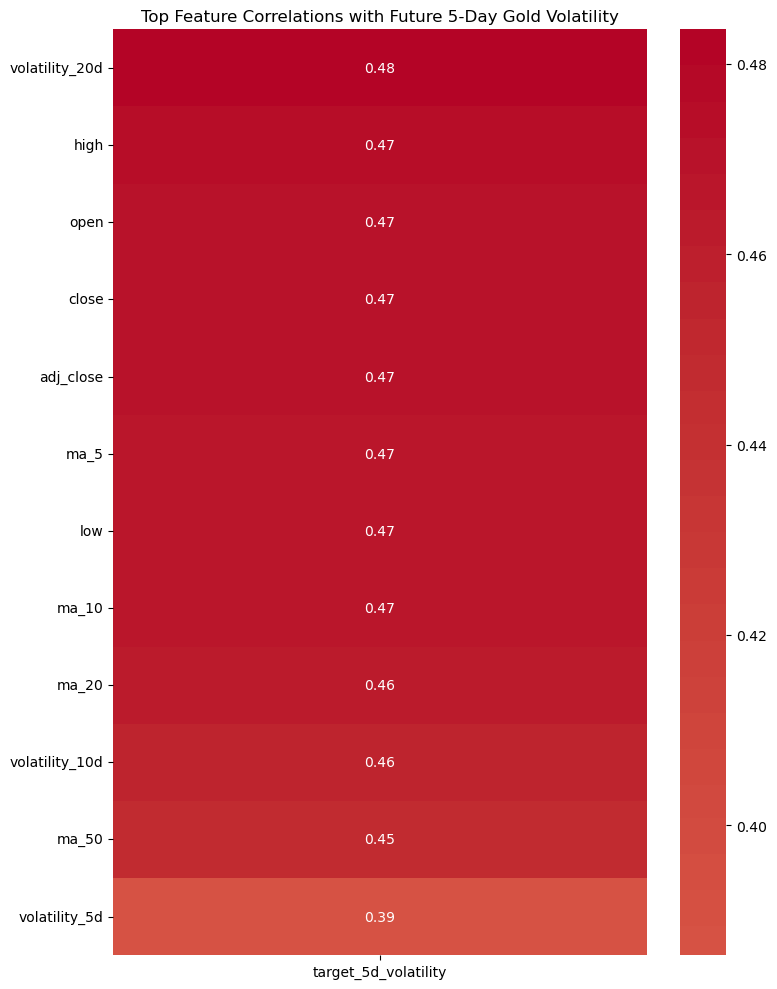

In [49]:
top_features = (
    strongest_features
    .head(12)
    .index
)

plt.figure(figsize=(8, 10))

sns.heatmap(
    correlation_matrix.loc[
        top_features,
        [target_column]
    ],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Top Feature Correlations with Future 5-Day Gold Volatility"
)

plt.tight_layout()
plt.show()

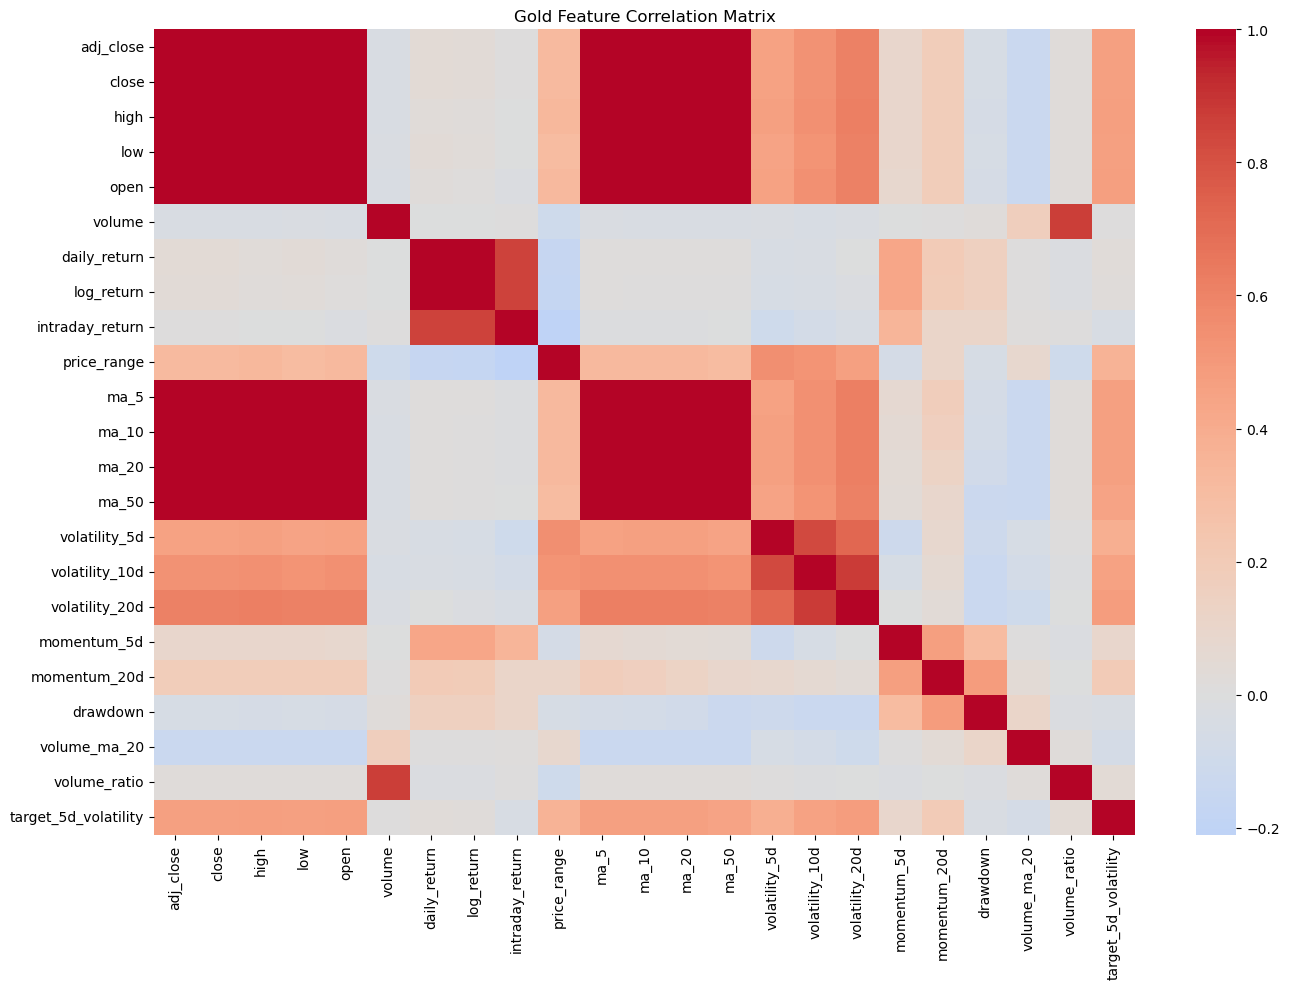

In [50]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Gold Feature Correlation Matrix")
plt.tight_layout()
plt.show()

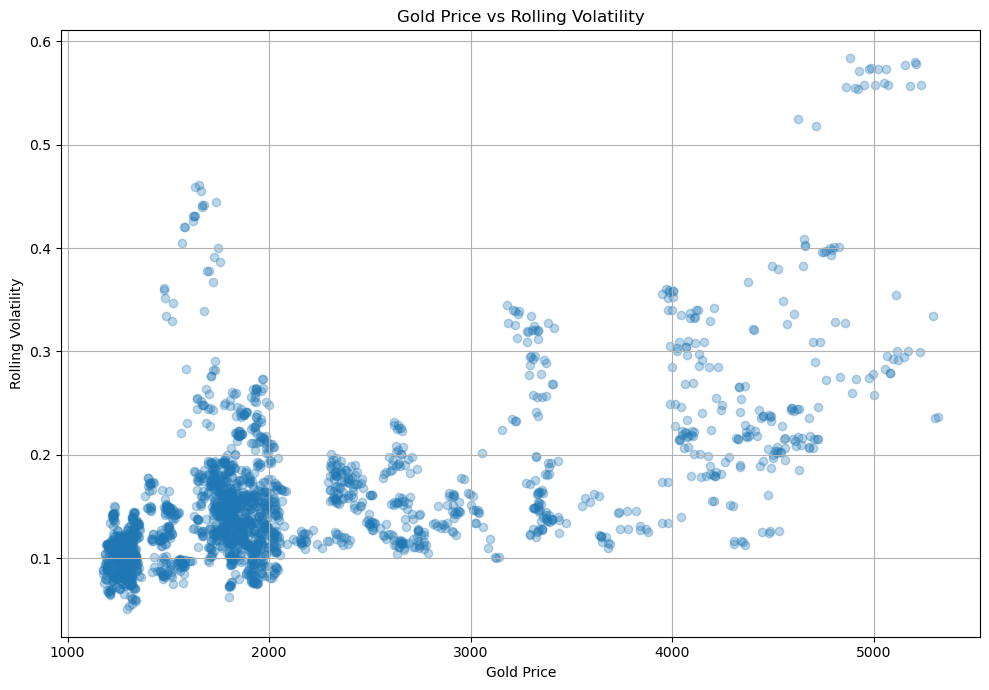

In [51]:
plt.figure(figsize=(10, 7))

plt.scatter(
    df[price_column],
    df[volatility_col],
    alpha=0.3
)

plt.title("Gold Price vs Rolling Volatility")
plt.xlabel("Gold Price")
plt.ylabel("Rolling Volatility")
plt.grid(True)
plt.tight_layout()
plt.show()

In [52]:
if "daily_return" in df.columns:

    largest_positive_returns = (
        df[
            ["date", "daily_return"]
        ]
        .dropna()
        .sort_values(
            "daily_return",
            ascending=False
        )
        .head(15)
    )

    largest_positive_returns

In [53]:
if "daily_return" in df.columns:

    largest_negative_returns = (
        df[
            ["date", "daily_return"]
        ]
        .dropna()
        .sort_values(
            "daily_return",
            ascending=True
        )
        .head(15)
    )

    largest_negative_returns

In [54]:
total_missing = df.isnull().sum().sum()

print("Total missing values:", total_missing)

Total missing values: 0


In [55]:
total_duplicates = df.duplicated().sum()

print("Total duplicate rows:", total_duplicates)

Total duplicate rows: 0


In [56]:
print(
    "Invalid dates:",
    df["date"].isna().sum()
)

print(
    "Dates sorted:",
    df["date"].is_monotonic_increasing
)

Invalid dates: 0
Dates sorted: True


In [57]:
print("=" * 60)
print("GOLD EDA SUMMARY")
print("=" * 60)

print("\nDataset:")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

print("\nData Quality:")
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nGold Price Statistics:")
print(df[price_column].describe())

print("\nAverage Daily Return:")
if "daily_return" in df.columns:
    print(df["daily_return"].mean())

print("\nAverage Rolling Volatility:")
print(df[volatility_col].mean())

print("\nAverage Future 5-Day Volatility:")
print(df[target_column].mean())

print("\nMaximum Drawdown:")
print(df["drawdown"].min())

print("\nEDA completed successfully.")

GOLD EDA SUMMARY

Dataset:
Rows: 2380
Columns: 24
Start date: 2017-03-15 00:00:00
End date: 2026-08-31 00:00:00

Data Quality:
Missing values: 0
Duplicate rows: 0

Gold Price Statistics:
count    2380.000000
mean     2097.873401
std       942.415265
min      1176.199951
25%      1425.250031
50%      1821.399963
75%      2312.699951
max      5318.399902
Name: close, dtype: float64

Average Daily Return:
0.000605674879461261

Average Rolling Volatility:
0.1535970802364365

Average Future 5-Day Volatility:
0.1444726653757989

Maximum Drawdown:
-0.250601652594825

EDA completed successfully.


In [58]:
eda_summary = pd.DataFrame({
    "metric": [
        "number_of_rows",
        "number_of_columns",
        "start_date",
        "end_date",
        "average_gold_price",
        "median_gold_price",
        "maximum_gold_price",
        "minimum_gold_price",
        "average_daily_return",
        "average_rolling_volatility",
        "average_future_5d_volatility",
        "maximum_drawdown"
    ],
    "value": [
        len(df),
        len(df.columns),
        str(df["date"].min()),
        str(df["date"].max()),
        df[price_column].mean(),
        df[price_column].median(),
        df[price_column].max(),
        df[price_column].min(),
        df["daily_return"].mean()
        if "daily_return" in df.columns else np.nan,
        df[volatility_col].mean(),
        df[target_column].mean(),
        df["drawdown"].min()
    ]
})

eda_summary

,metric,value
0,number_of_rows,2380
1,number_of_columns,24
2,start_date,2017-03-15 00:00:00
3,end_date,2026-08-31 00:00:00
4,average_gold_price,2097.873401
5,median_gold_price,1821.399963
6,maximum_gold_price,5318.399902
7,minimum_gold_price,1176.199951
8,average_daily_return,0.000606
9,average_rolling_volatility,0.153597


In [59]:
summary_path = Path(
    "../data/processed/gold_eda_summary.csv"
)

eda_summary.to_csv(
    summary_path,
    index=False
)

print("EDA summary saved to:")
print(summary_path)

EDA summary saved to:
..\data\processed\gold_eda_summary.csv
